In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('mldataset_v1.csv')
df.columns = df.columns.str.strip()

---

## 4. Data PreProcessing

### 4.1 Memeriksa Missing Value dan Duplikat Data -> Menghapus Missing Value dan Duplikat Data Jika Tersedia

In [40]:
df.isnull().sum().sum()

np.int64(0)

In [41]:
df.duplicated().sum()

np.int64(210)

In [42]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

df.duplicated().sum()

np.int64(0)

### 4.2 Memisahkan Kolom Fitur ($X$) dan Kolom Target ($y$)

In [43]:
X = df.drop(columns=['label'])
y = df['label']

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk Y : {len(y)} label")

Bentuk X : 390 baris, 333 kolom
Bentuk Y : 390 label


### 4.3 Memeriksa Nilai Negatif pada Kolom Fitur ($X$) & Melihat Nilai Terkecil dan Nilai Terbesar pada Kolom Fitur

In [44]:
nilai_negatif = (X < 0).any().any()
if nilai_negatif:
    print("Ditemukan nilai negatif pada fitur")
else:
    print("Semua nilai fitur bernilai non-negatif")

print(f"Nilai Terkecil : {X.values.min()}")
print(f"Nilai Terbesar : {X.values.max()}")

Semua nilai fitur bernilai non-negatif
Nilai Terkecil : 0
Nilai Terbesar : 1


### 4.4 Membagi Data Latih (80%) dan Data Uji (20%) 

In [45]:
np.random.seed(43)

indeks_acak = np.random.permutation(len(X))
batas = int(0.8 * len(X))

X_train = X.iloc[indeks_acak[:batas]].reset_index(drop=True)
X_test = X.iloc[indeks_acak[batas:]].reset_index(drop=True)

y_train = y.iloc[indeks_acak[:batas]].reset_index(drop=True)
y_test = y.iloc[indeks_acak[batas:]].reset_index(drop=True)

print(f"Data Latih  : {len(X_train)} baris (80%)")
print(f"Data Uji    : {len(X_test)} baris (20%)")

Data Latih  : 312 baris (80%)
Data Uji    : 78 baris (20%)


### 4.5 Menangani Input Teks Baru untuk GUI

In [ ]:
daftar_fitur =  X.columns.tolist()

def ubah_teks(teks_input):
    teks_bersih = ''.join([huruf.lower() if huruf.isalnum() else '' for huruf in teks_input])
    daftar_kata = teks_bersih.split()

    vektor_kata = {kata: 0 for kata in daftar_fitur}
    for kata in daftar_kata:
        if kata in vektor_kata:
            vektor_kata[kata] += 1

    return pd.DataFrame([vektor_kata])

---

## 5. Modelling Naive Bayes (Multinomial)

### 5.1 Menghitung Probabilitas Prior

In [48]:
total = len(y_train)
jumlah_kelas = y_train.value_counts().sort_index()
prior = jumlah_kelas / total

for kelas, nilai in prior.items():
    print(f"Prior Kelas {kelas}: {nilai:.4f}")

Prior Kelas 1: 0.2212
Prior Kelas 2: 0.2115
Prior Kelas 3: 0.2019
Prior Kelas 4: 0.1410
Prior Kelas 5: 0.1250
Prior Kelas 6: 0.0994


### 5.2 Menghitung Probabilitas Likelihood

In [54]:
V = X_train.shape[1]
likelihood = {}

for kelas in prior.index:
    data_kelas = X_train[y_train == kelas]
    frek_kata = data_kelas.sum(axis=0)
    total_kata = data_kelas.values.sum()
    likelihood[kelas] = (frek_kata + 1) / (total_kata + V)

df_likelihood = pd.DataFrame(likelihood)
print("Contoh Nilai Likelihood untuk 5 Kata Pertama: ")
print(df_likelihood.head())

Contoh Nilai Likelihood untuk 5 Kata Pertama: 
              1         2         3         4         5         6
to     0.046823  0.044341  0.043866  0.039683  0.038647  0.034820
based  0.042809  0.040371  0.040439  0.035273  0.034783  0.031556
on     0.042809  0.040371  0.040439  0.035273  0.034783  0.031556
of     0.034114  0.032429  0.032214  0.031746  0.029952  0.025027
their  0.029431  0.026473  0.026731  0.024691  0.022222  0.023939


### 5.3 Menghitung Posterior 

In [56]:
def tebakan(baris_kata):
    skor = {}

    for kelas in prior.index:
        prior_ket = np.log(prior[kelas])
        likelihood_ket = np.sum(baris_kata * np.log(df_likelihood[kelas]))
        skor[kelas] = prior_ket + likelihood_ket

    return max(skor, key=skor.get)

y_pred = [tebakan(baris) for _, baris in X_test.iterrows()]
y_pred = pd.Series(y_pred, index=X_test.index)

print("Contoh 10 Hasil Tebakan Model: ", y_pred.head(10).tolist())
print("Contoh 10 Kunci Jawaban Asli : ", y_test.head(10).tolist())

Contoh 10 Hasil Tebakan Model:  [4, 2, 3, 1, 5, 4, 6, 1, 2, 1]
Contoh 10 Kunci Jawaban Asli :  [4, 2, 3, 1, 5, 5, 6, 1, 2, 1]


---

## 6. Evaluation

### 6.1 Menghitung Accuracy, Precision, Recall, F1-Score pada Model Naive Bayes (Multinomial)

In [73]:
prediksi_benar = (y_pred == y_test).sum()
total_data_uji = len(y_test)
skor_akurasi = (prediksi_benar / total_data_uji) 

print(f"Jumlah Prediksi Benar   : {prediksi_benar} dari {total_data_uji}")
print(f"Hasil Accuracy Model     : {skor_akurasi:.2%}\n")

table_eval = []

for kelas in prior.index:
    tp = ((y_pred == kelas) & (y_test == kelas)).sum()
    total_tebakan = (y_pred == kelas).sum()
    total_asli = (y_test == kelas).sum()

    precision = tp / total_tebakan
    recall = tp / total_asli
    f1_score = ((2 * precision * recall) / (precision + recall))

    table_eval.append({"Kelas": f"Kelas {kelas}", "Precision": f"{precision:.2f}", "Recall": f"{recall:.2f}", "F1-Score": f"{f1_score:.2f}", "Jumlah Asli": total_asli})

df_eval = pd.DataFrame(table_eval)
print(df_eval.to_string(index=False))

Jumlah Prediksi Benar   : 70 dari 78
Hasil Accuracy Model     : 89.74%

  Kelas Precision Recall F1-Score  Jumlah Asli
Kelas 1      1.00   0.94     0.97           16
Kelas 2      1.00   1.00     1.00           11
Kelas 3      1.00   1.00     1.00           14
Kelas 4      0.69   0.85     0.76           13
Kelas 5      0.86   0.71     0.77           17
Kelas 6      0.88   1.00     0.93            7


### 6.2 Visualisasi Evaluasi Confusion Matrix dan Perbandingan Metrik Evaluasi Model

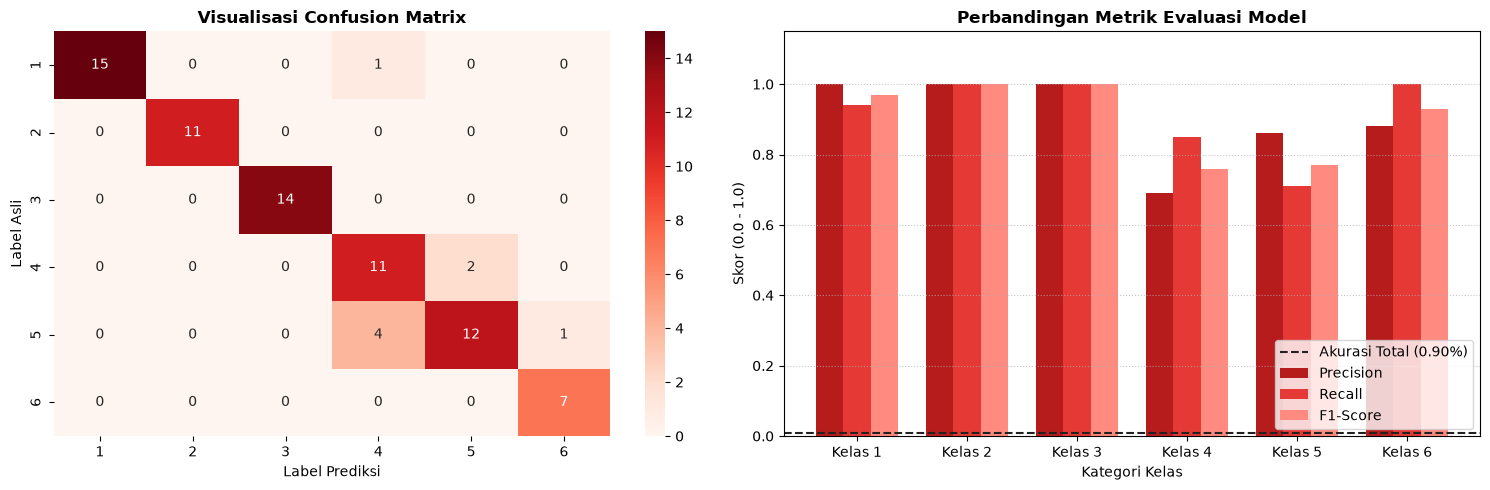

In [71]:
confusion_matrix = pd.crosstab(y_test, y_pred)

kelas = df_eval['Kelas']
precision = df_eval['Precision'].astype(float)
recall = df_eval['Recall'].astype(float)
f1 = df_eval['F1-Score'].astype(float)
posisi = np.arange(len(kelas))
lebar = 0.25

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Reds', ax=axes[0])
axes[0].set_title("Visualisasi Confusion Matrix", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Label Prediksi")
axes[0].set_ylabel("Label Asli")
axes[1].bar(posisi - lebar, precision, width=lebar, label='Precision', color='#B71C1C')
axes[1].bar(posisi, recall, width=lebar, label='Recall', color='#E53935')
axes[1].bar(posisi + lebar, f1, width=lebar, label='F1-Score', color='#FF8A80')

skor_akurasi_desimal = skor_akurasi / 100
axes[1].axhline(skor_akurasi_desimal, color='#212121', linestyle='--', linewidth=1.5,
                label=f'Akurasi Total ({skor_akurasi:.2f}%)')

axes[1].set_title("Perbandingan Metrik Evaluasi Model", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Kategori Kelas")
axes[1].set_ylabel("Skor (0.0 - 1.0)")
axes[1].set_xticks(posisi)
axes[1].set_xticklabels(kelas)
axes[1].set_ylim(0, 1.15)
axes[1].legend(loc='lower right')
axes[1].grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

---

## 7. Conclution

### 7.1 Kesimpulan Analisis dan Permodelan